# Credit Card Fraud Detection using Deep Neural Network

**Proyek Mata Kuliah Pembelajaran Mendalam (Semester Ganjil, TA 2026-2027)** — Tugas Proyek 1,
dilanjutkan dan disempurnakan untuk Ujian Tengah Semester (UTS)

| | |
|---|---|
| Nama kelompok | Blueprints |
| Kelas | IF B Sore |
| Dataset | [Credit Card Fraud Detection — ULB (Kaggle)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) |
| Model | Deep Neural Network / Multi-Layer Perceptron (TensorFlow/Keras) |

### Anggota kelompok dan pembagian tugas

| NIM | Nama | Peran | Rincian pekerjaan |
|---|---|---|---|
| 231112189 | Nanda Fachriza Artin | Ketua & ML Engineer | Arsitektur DNN, Focal Loss, pelatihan semua skenario, pemilihan model final |
| 231110155 | Arman Maulana | Data Analyst | Verifikasi dataset, EDA, analisis distribusi kelas, korelasi, outlier |
| 231110255 | Nyoto Prasetyo | Data Engineer | Pembersihan data, rekayasa fitur, split, scaling, pipeline `tf.data` |
| 231112549 | Mhd. Abi Manyu | Evaluator | Optimasi threshold, metrik, perbandingan skenario, analisis kesalahan |
| 231110656 | Celvin | App Developer & Deployment | Kompresi TFLite, aplikasi Streamlit, notebook Colab, README repositori |

### Alur notebook (sesuai langkah pengerjaan RTM)
1. Persiapan lingkungan dan dataset
2. Eksplorasi data (EDA)
3. Praproses data: pembersihan, normalisasi, pembagian data latih/validasi/uji
4. Representasi tensor dan **pipeline input `tf.data`**
5. Arsitektur **Multi-Layer Perceptron (MLP/DNN)**
6. Pelatihan dengan teknik optimasi & regulasi: loss function, dropout, batch normalization,
   optimizer Adam/RMSProp, *learning rate scheduling*, *early stopping*
7. Evaluasi (accuracy, precision, recall, F1, confusion matrix) dan iterasi perbaikan model
8. Fitur unik: optimasi threshold & kompresi TFLite
9. Inferensi dan aplikasi
10. Penyempurnaan UTS: validasi input dan penjelasan prediksi

> **Cara menjalankan di Google Colab:** File → Upload notebook → pilih file ini, lalu
> *Runtime → Run all*. Pelatihan 14 run memakan waktu sekitar 20–25 menit di CPU. Untuk
> demo cepat, ubah `LATIH_ULANG = False` agar notebook memakai model yang sudah dilatih.
> Hasil pelatihan ulang di Colab bisa sedikit berbeda dari laporan karena perbedaan
> versi library dan perangkat keras; angka resmi laporan ada di `outputs/results/`.

## 1. Persiapan lingkungan dan dataset

**Di Google Colab** cukup jalankan sel-sel di bawah secara berurutan (*Runtime → Run all*).
Kode proyek diambil dengan salah satu cara berikut (otomatis dicoba berurutan):
1. *clone* dari GitHub bila `REPO_URL` sudah diisi link repo kelompok;
2. file `Source_Code_Credit_Card_Fraud_DNN.zip` yang ada di Google Drive (`MyDrive/`);
3. bila keduanya tidak ada, Colab akan meminta Anda **mengunggah** file zip tersebut.

Dataset yang dipakai adalah file asli Kaggle (`mlg-ulb/creditcardfraud`) yang disimpan di
repositori sebagai `data/creditcard_kaggle.zip.part1–3` (dipecah agar setiap file < 25 MB).
Sel dataset menggabungkan dan mengekstraknya menjadi `data/creditcard.csv` lalu memeriksa
checksum MD5-nya. Bila bagian tersebut tidak ada, dataset dicari di Google Drive, diunduh dari
Kaggle (`kagglehub`), atau Anda diminta mengunggah `creditcard.csv`.
Library yang dibutuhkan (TensorFlow, scikit-learn, pandas, matplotlib) **sudah tersedia di
Colab**, sehingga tidak perlu `pip install` apa pun.

In [1]:
import os, sys, shutil, zipfile, subprocess
from pathlib import Path

REPO_URL = ""            # isi, misal "https://github.com/<username>/credit-card-fraud-dnn.git"
ZIP_NAME = "Source_Code_Credit_Card_Fraud_DNN.zip"
LATIH_ULANG = True       # False = pakai model & hasil yang sudah tersimpan (±1 menit)
IN_COLAB = "google.colab" in sys.modules


def extract(zip_path, dest):
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(dest)
    # jika zip berisi satu folder induk, pakai folder itu sebagai root
    kids = [k for k in dest.iterdir() if not k.name.startswith(("_", "."))]
    if len(kids) == 1 and kids[0].is_dir() and not (dest / "src").exists():
        return kids[0]
    return dest


if IN_COLAB:
    ROOT = Path("/content/credit-card-fraud-dnn")
    if not (ROOT / "src").exists():
        if REPO_URL:
            subprocess.run(["git", "clone", REPO_URL, str(ROOT)], check=True)
        else:
            from google.colab import drive
            drive.mount("/content/drive")
            found = list(Path("/content/drive/MyDrive").rglob(ZIP_NAME))
            if found:
                zp = found[0]
            else:
                from google.colab import files
                print(f"Unggah file {ZIP_NAME} ...")
                up = files.upload()
                zp = Path(next(iter(up)))
            ROOT.mkdir(parents=True, exist_ok=True)
            ROOT = extract(zp, ROOT)
else:
    ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
print("Root proyek:", ROOT)
print(sorted(p.name for p in ROOT.iterdir()))

Root proyek: /home/claude/proj
['.gitignore', '.streamlit', 'README.md', 'app', 'data', 'docs', 'notebooks', 'outputs', 'report', 'requirements.txt', 'src']


In [2]:
# Dataset: salinan asli Kaggle di repo (data/creditcard_kaggle.zip.part*) -> Drive -> Kaggle -> unggah
DATA = ROOT / "data" / "creditcard.csv"
DATA.parent.mkdir(exist_ok=True)
if not DATA.exists() and list((ROOT / "data").glob("creditcard_kaggle.zip.part*")):
    from get_dataset import ensure_dataset
    ensure_dataset()
if not DATA.exists() and IN_COLAB:
    mydrive = Path("/content/drive/MyDrive")
    drive_csv = list(mydrive.rglob("creditcard.csv")) if mydrive.exists() else []
    if drive_csv:
        shutil.copy(drive_csv[0], DATA)
if not DATA.exists():
    try:
        import kagglehub
        path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
        shutil.copy(Path(path) / "creditcard.csv", DATA)
    except Exception as e:
        print("Unduh dari Kaggle gagal:", e)
        if IN_COLAB:
            from google.colab import files
            print("Unggah file creditcard.csv ...")
            up = files.upload()
            shutil.move(next(iter(up)), DATA)
assert DATA.exists(), "creditcard.csv belum tersedia"
print(DATA, f"{DATA.stat().st_size/1e6:.1f} MB")

Digabung dari 3 bagian -> /home/claude/proj/data/creditcard.csv (150,828,752 byte), MD5 cocok dengan file asli Kaggle
/home/claude/proj/data/creditcard.csv 150.8 MB


In [3]:
import platform, json
import numpy as np, pandas as pd, tensorflow as tf, sklearn, matplotlib
from IPython.display import Image, display
print("Python      :", platform.python_version())
print("TensorFlow  :", tf.__version__)
print("scikit-learn:", sklearn.__version__)
print("pandas      :", pd.__version__, "| numpy:", np.__version__, "| matplotlib:", matplotlib.__version__)
print("GPU         :", tf.config.list_physical_devices("GPU") or "tidak ada (CPU)")

import config
FIG, RES, MOD = config.FIG_DIR, config.RESULT_DIR, config.MODEL_DIR
show = lambda name, w=900: display(Image(filename=str(FIG / name), width=w))
print({k: getattr(config, k) for k in ["SEED", "TEST_SIZE", "VAL_SIZE", "BATCH_SIZE",
                                        "EPOCHS", "LEARNING_RATE", "PATIENCE"]})

I0000 00:00:1794239438.587970    1732 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794239438.695789    1732 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794239439.935391    1732 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python      : 3.13.18
TensorFlow  : 2.21.0
scikit-learn: 1.9.1
pandas      : 3.0.5 | numpy: 2.5.3 | matplotlib: 3.11.2
GPU         : tidak ada (CPU)
{'SEED': 42, 'TEST_SIZE': 0.15, 'VAL_SIZE': 0.15, 'BATCH_SIZE': 2048, 'EPOCHS': 100, 'LEARNING_RATE': 0.001, 'PATIENCE': 10}


## 2. Exploratory Data Analysis (EDA)
Skrip `src/eda.py` menghitung statistik, mendeteksi duplikat & outlier, serta menyimpan grafik.

In [4]:
raw = pd.read_csv(DATA)
print(raw.shape)
display(raw.head())
display(raw["Class"].value_counts().rename({0: "Normal", 1: "Fraud"}).to_frame("jumlah"))

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


,jumlah
Class,
Normal,284315
Fraud,492


In [5]:
import eda
eda.main()

{
  "shape_raw": [
    284807,
    31
  ],
  "rows_raw": 284807,
  "missing_values": 0,
  "duplicates": 1081,
  "duplicates_fraud": 19,
  "rows_clean": 283726,
  "class_counts_raw": {
    "0": 284315,
    "1": 492
  },
  "fraud_ratio_raw_pct": 0.1727,
  "amount_stats": {
    "count": 284807.0,
    "mean": 88.35,
    "std": 250.12,
    "min": 0.0,
    "25%": 5.6,
    "50%": 22.0,
    "75%": 77.16,
    "max": 25691.16
  },
  "amount_by_class": {
    "0": {
      "count": 284315.0,
      "mean": 88.29,
      "std": 250.11,
      "min": 0.0,
      "25%": 5.65,
      "50%": 22.0,
      "75%": 77.05,
      "max": 25691.16
    },
    "1": {
      "count": 492.0,
      "mean": 122.21,
      "std": 256.68,
      "min": 0.0,
      "25%": 1.0,
      "50%": 9.25,
      "75%": 105.89,
      "max": 2125.87
    }
  },
  "time_max_hours": 48.0,
  "amount_zero": 1825,
  "fraud_rate_by_hour_pct": {
    "0": 0.078,
    "1": 0.237,
    "2": 1.713,
    "3": 0.487,
    "4": 1.041,
    "5": 0.368,
    "6": 0

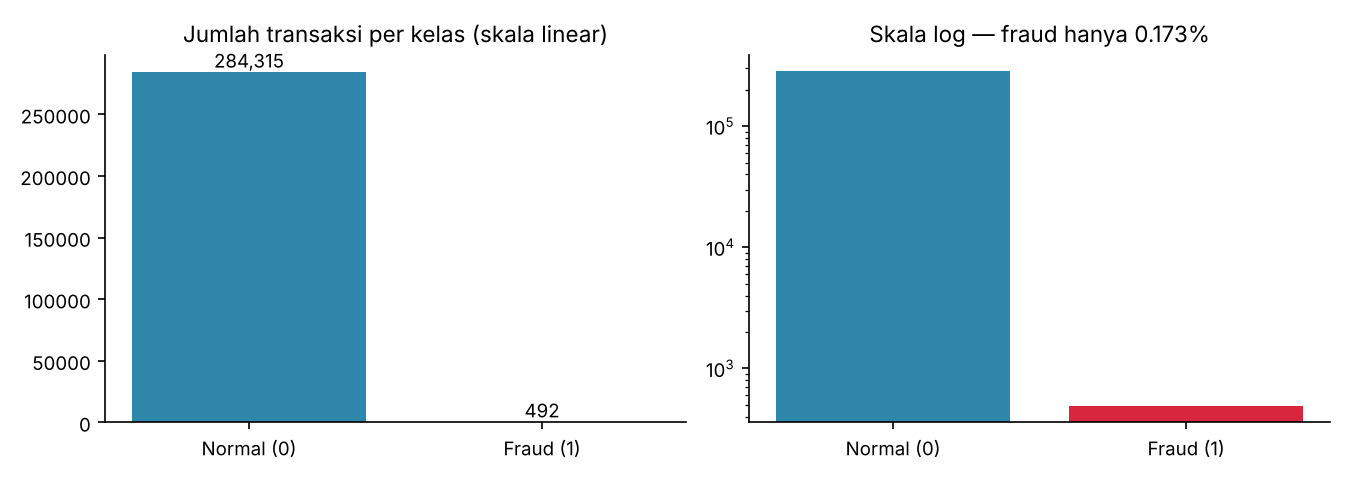

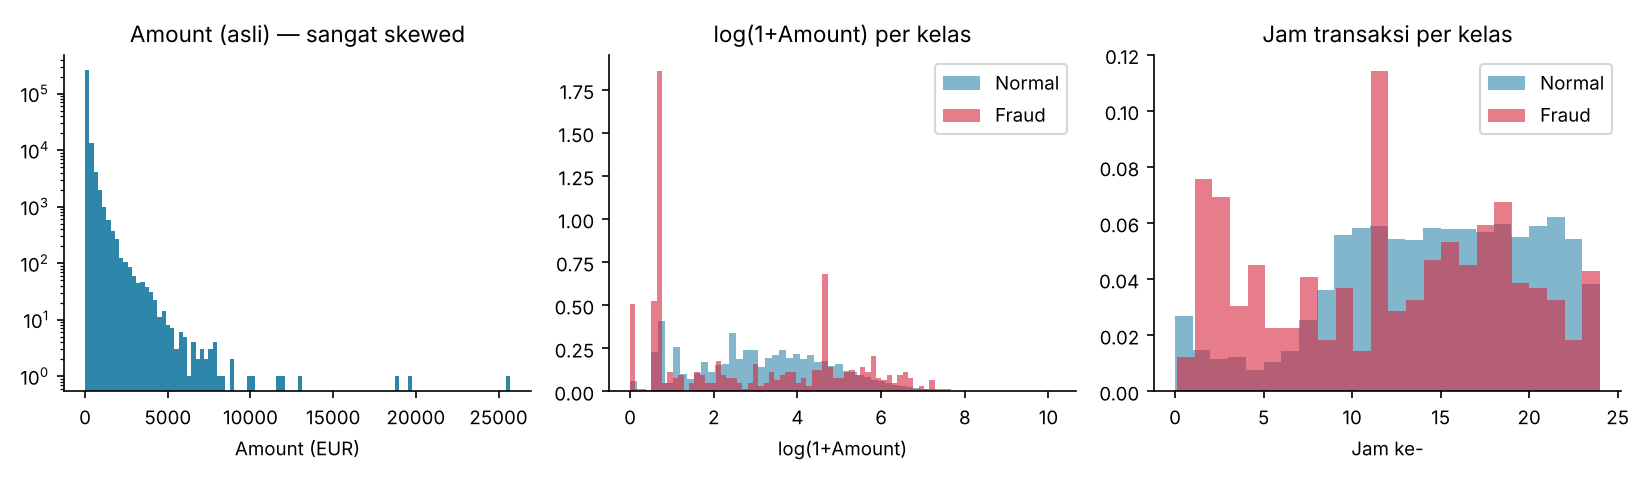

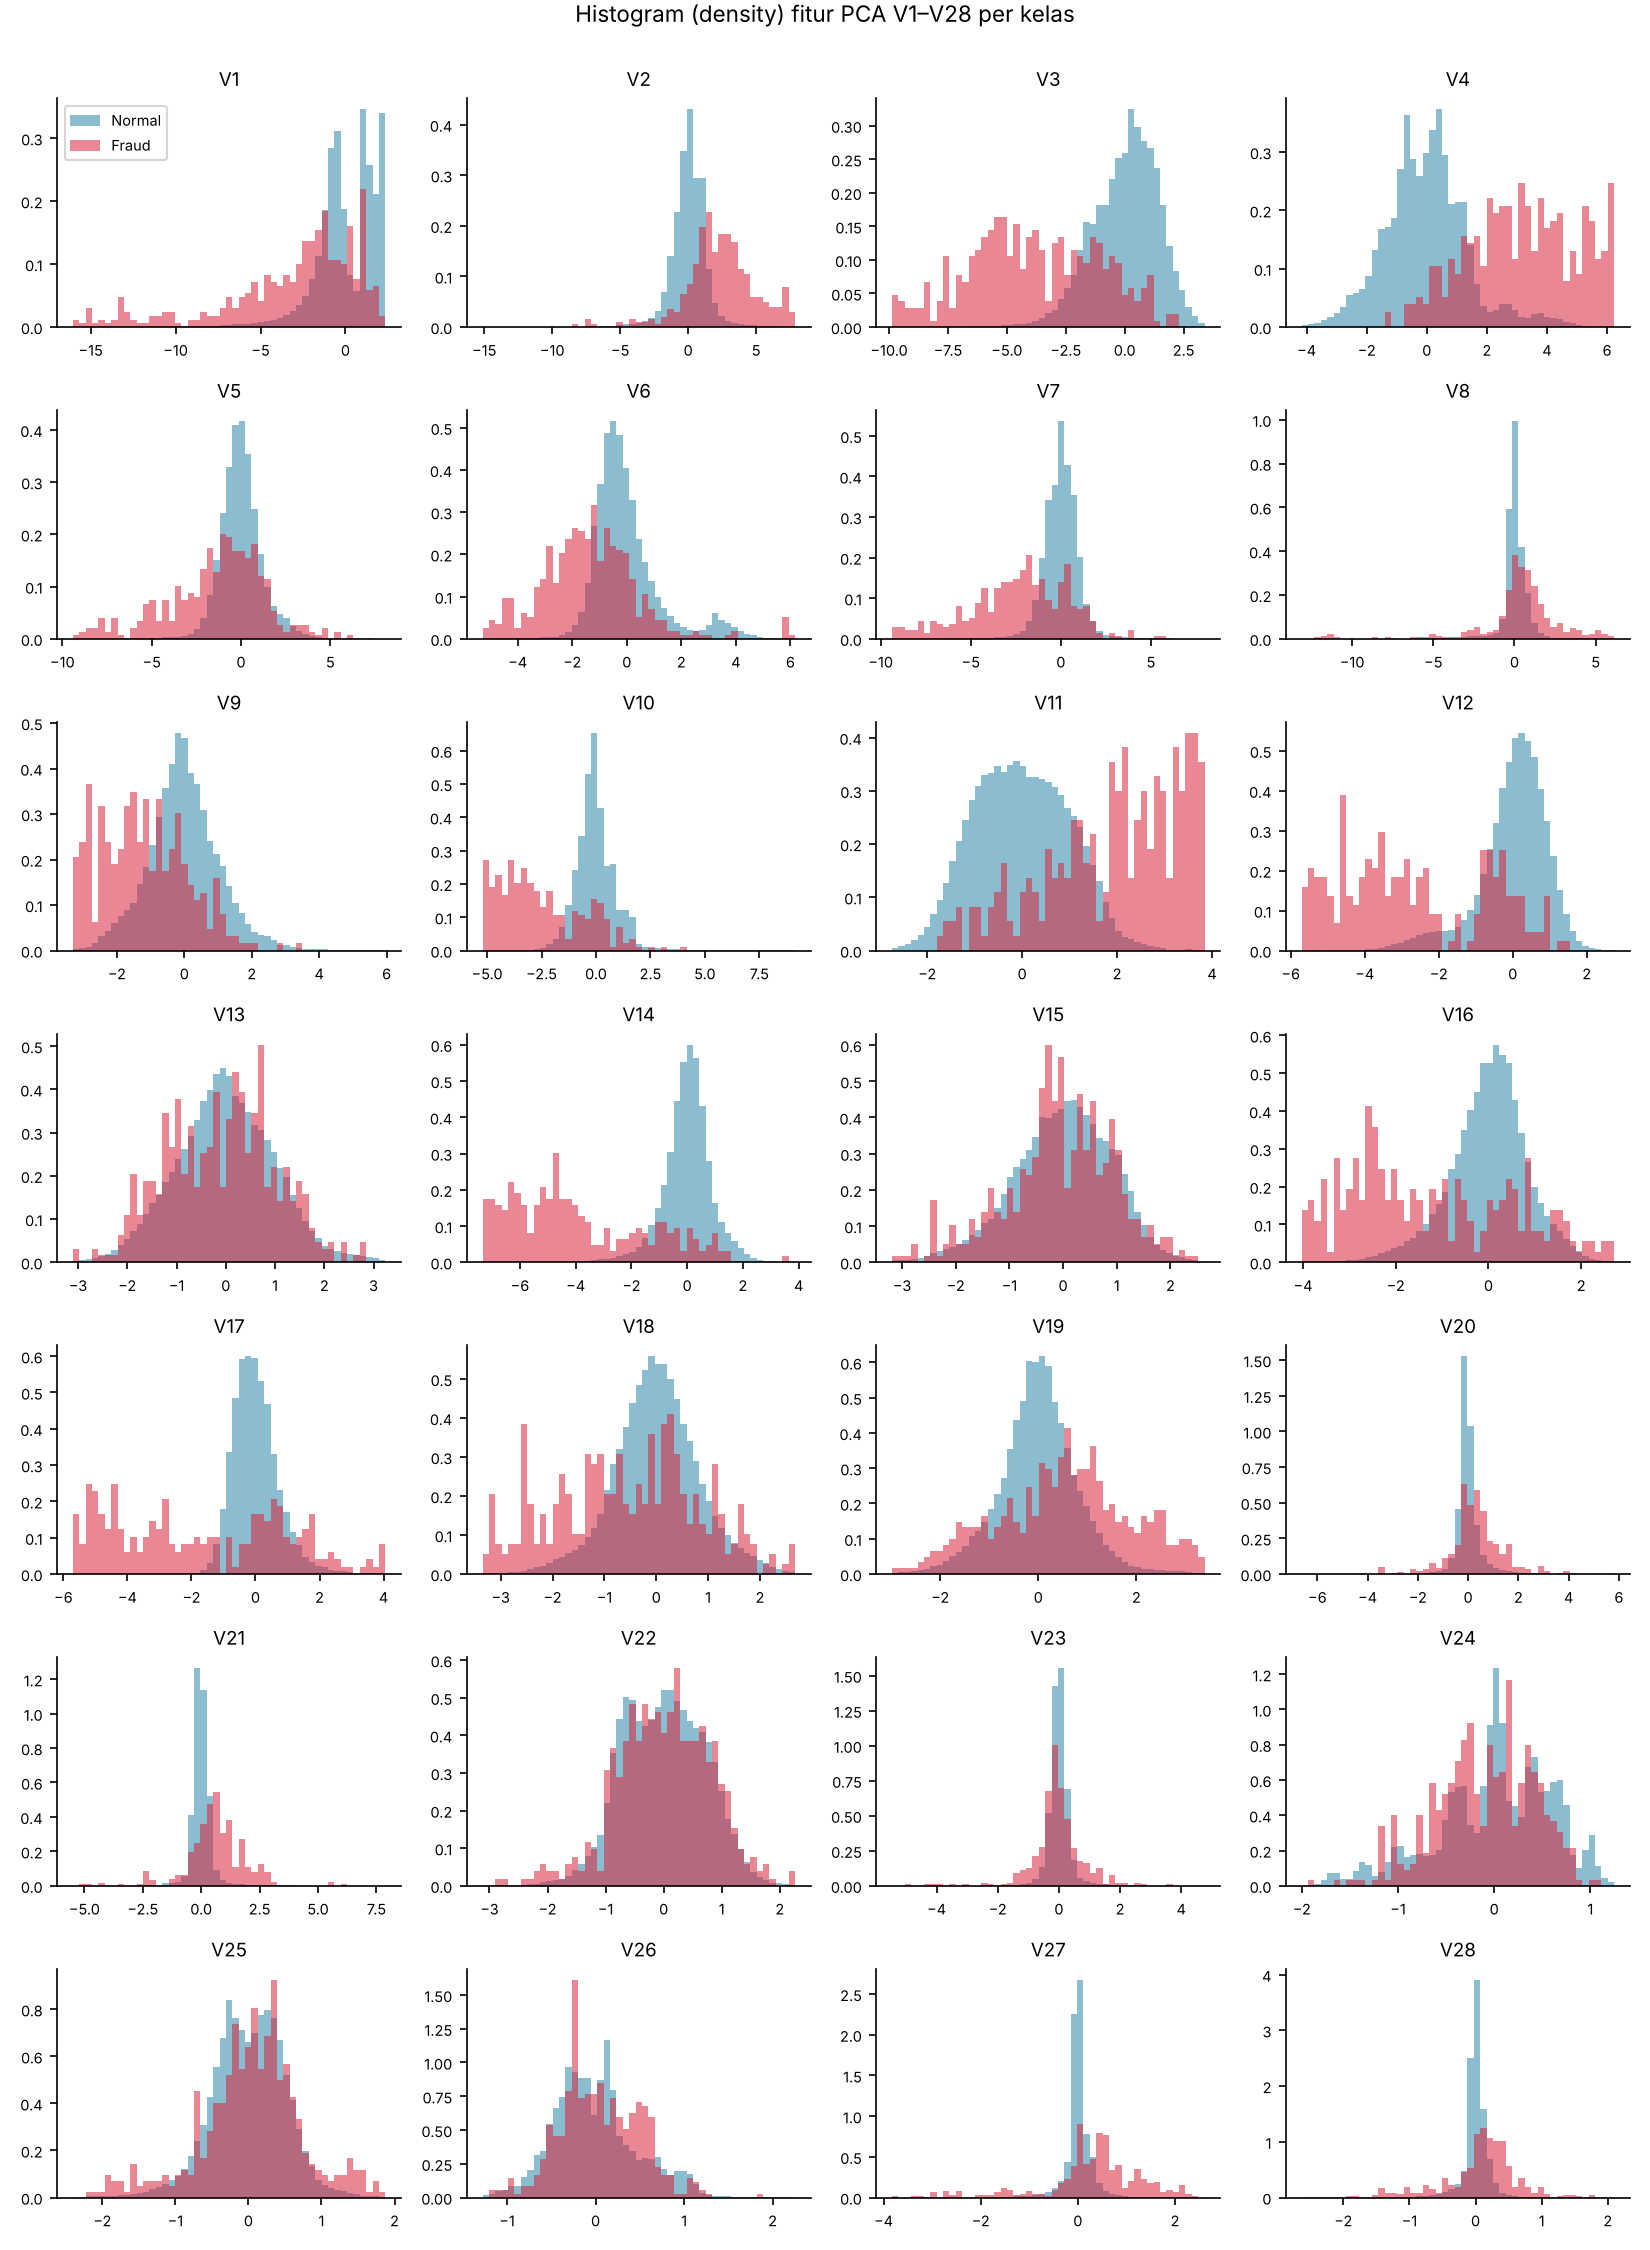

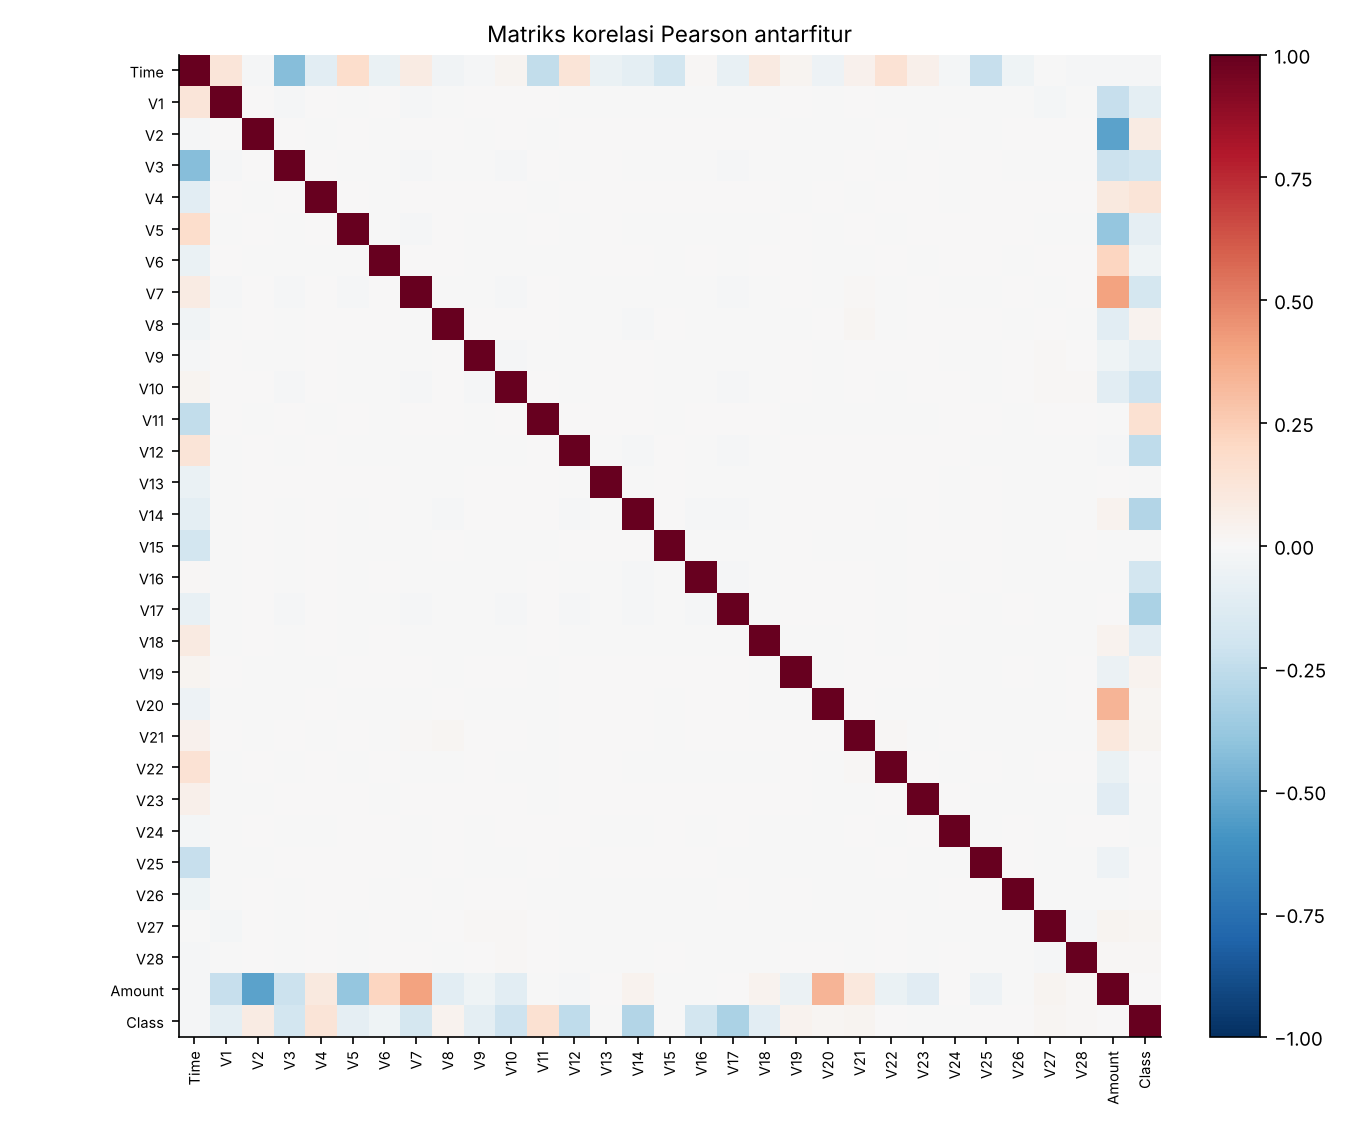

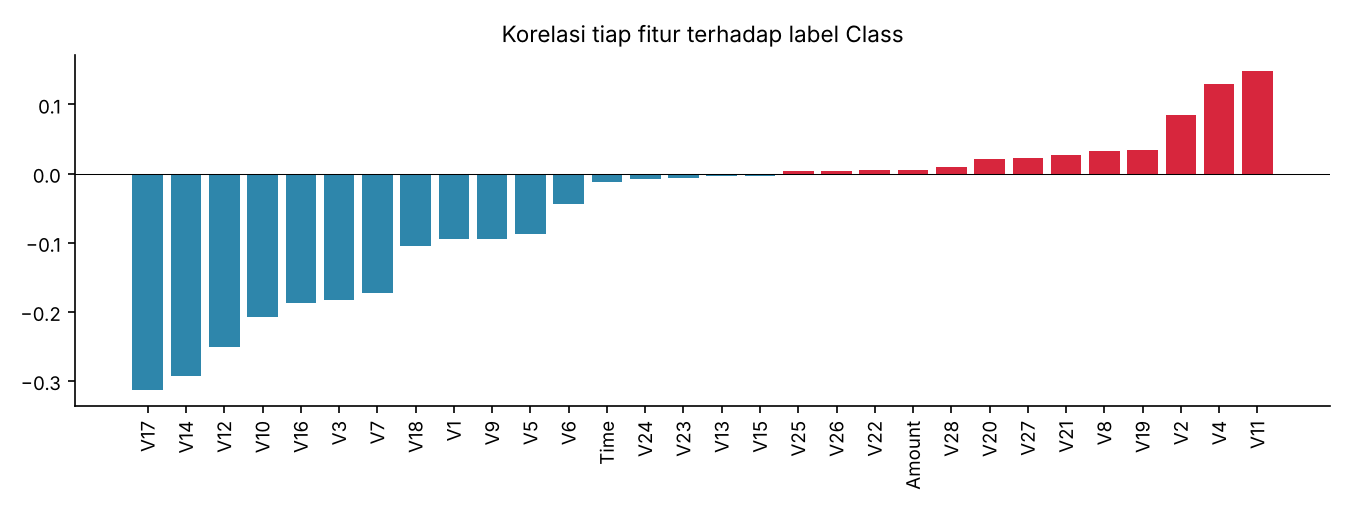

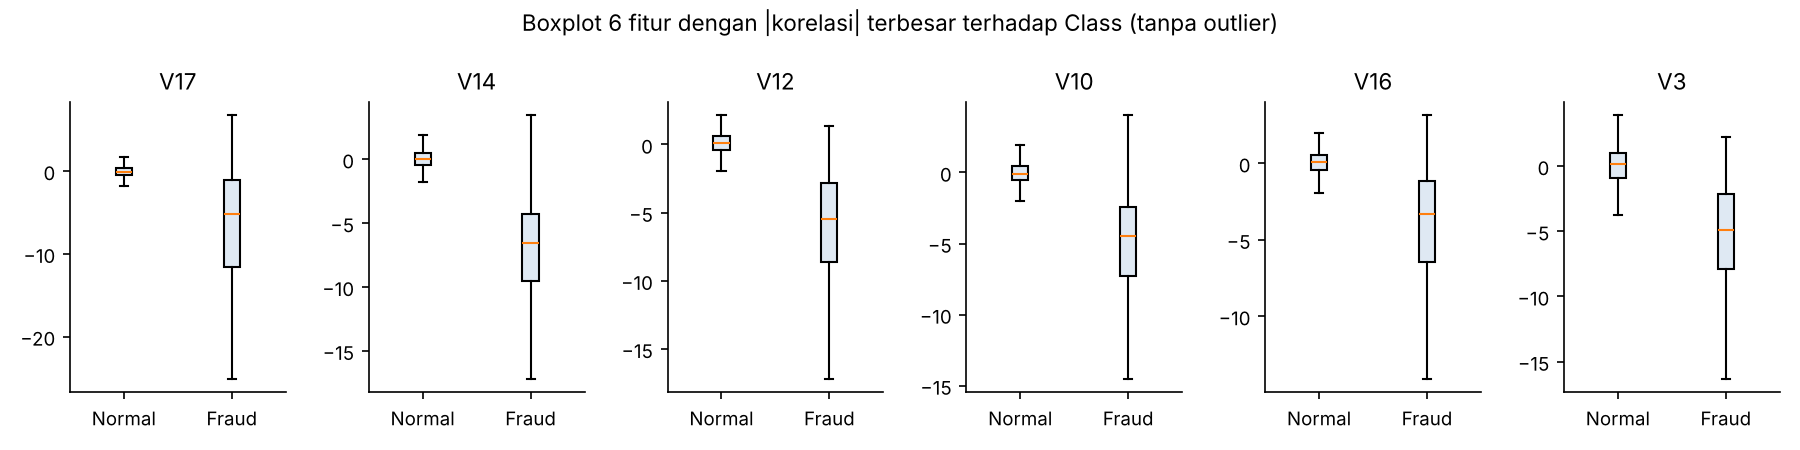

In [6]:
for f in ["eda_01_class_distribution.png", "eda_02_amount_time.png", "eda_03_hist_V.png",
          "eda_04_corr_heatmap.png", "eda_05_corr_class.png", "eda_06_boxplot_top.png"]:
    show(f, 800 if f != "eda_03_hist_V.png" else 700)

## 3. Praproses data
Urutan: **hapus duplikat → rekayasa fitur → split stratified 70/15/15 → StandardScaler
(fit hanya di data latih)**, sehingga tidak ada kebocoran data.
- `Amount` → `log(1+Amount)` (distribusi sangat skewed)
- `Time` → jam dalam sehari, dikodekan siklik `sin`/`cos`

In [7]:
from preprocessing import prepare_all, FEATURES
data, info = prepare_all()
X_train, X_val, X_test, y_train, y_val, y_test = data
print("Fitur (%d):" % len(FEATURES), FEATURES)
pd.DataFrame({
    "jumlah": [info["n_train"], info["n_val"], info["n_test"]],
    "fraud": [info["fraud_train"], info["fraud_val"], info["fraud_test"]],
}, index=["train", "validation", "test"]).assign(pct_fraud=lambda d: 100 * d.fraud / d.jumlah)

Fitur (31): ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'LogAmount', 'Hour_sin', 'Hour_cos']


,jumlah,fraud,pct_fraud
train,198608,331,0.166660
validation,42559,71,0.166827
test,42559,71,0.166827


In [8]:
print("Duplikat dihapus:", info["duplicates"], "| baris bersih:", info["rows_clean"])
print("Rata-rata fitur train setelah scaling (≈0):", X_train.mean(0)[:5].round(3))
print("Std fitur train setelah scaling (≈1)     :", X_train.std(0)[:5].round(3))

Duplikat dihapus: 1081 | baris bersih: 283726
Rata-rata fitur train setelah scaling (≈0): [-0.  0.  0. -0.  0.]
Std fitur train setelah scaling (≈1)     : [1. 1. 1. 1. 1.]


## 4. Representasi tensor dan pipeline input `tf.data`
Data tabular direpresentasikan sebagai tensor 2D berbentuk `(jumlah_transaksi, 31)` bertipe
`float32`. Pipeline `tf.data` (`src/data_pipeline.py`):
`from_tensor_slices → cache → shuffle (train) → batch(2048) → prefetch(AUTOTUNE)`.

In [9]:
from data_pipeline import make_dataset
t = tf.convert_to_tensor(X_train)
print("Tensor X_train:", t.shape, t.dtype, "| rank:", tf.rank(t).numpy())
print("Contoh 1 transaksi (5 fitur pertama):", t[0, :5].numpy())

ds_train = make_dataset(X_train, y_train, config.BATCH_SIZE, shuffle=True, seed=config.SEED)
ds_val = make_dataset(X_val, y_val, config.BATCH_SIZE)
print("element_spec:", ds_train.element_spec)
print("jumlah batch train/val:", ds_train.cardinality().numpy(), ds_val.cardinality().numpy())
xb, yb = next(iter(ds_train))
print("satu batch:", xb.shape, yb.shape, "| fraud dalam batch:", int(tf.reduce_sum(yb)))

Tensor X_train: (198608, 31) <dtype: 'float32'> | rank: 2
Contoh 1 transaksi (5 fitur pertama): [ 0.58340096  0.12089057  0.2370719   0.41643128 -0.2037546 ]
element_spec: (TensorSpec(shape=(None, 31), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))
jumlah batch train/val: 97 21


satu batch: (2048, 31) (2048,) | fraud dalam batch: 3


## 5. Arsitektur Multi-Layer Perceptron (DNN)
`Input(31) → [Dense → BatchNorm → ReLU → Dropout] × 3 (64-32-16) → Dense(1, sigmoid)`,
regularisasi L2 1e-4, bias output awal = log(pos/neg).

Model: "fraud_dnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ fitur_transaksi (InputLayer)    │ (None, 31)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 32)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (Activation)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_3 (BatchNormalization)       │ (None, 16)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_3 (Activation)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prob_fraud (Dense)              │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,121 (20.00 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 224 (896.00 B)

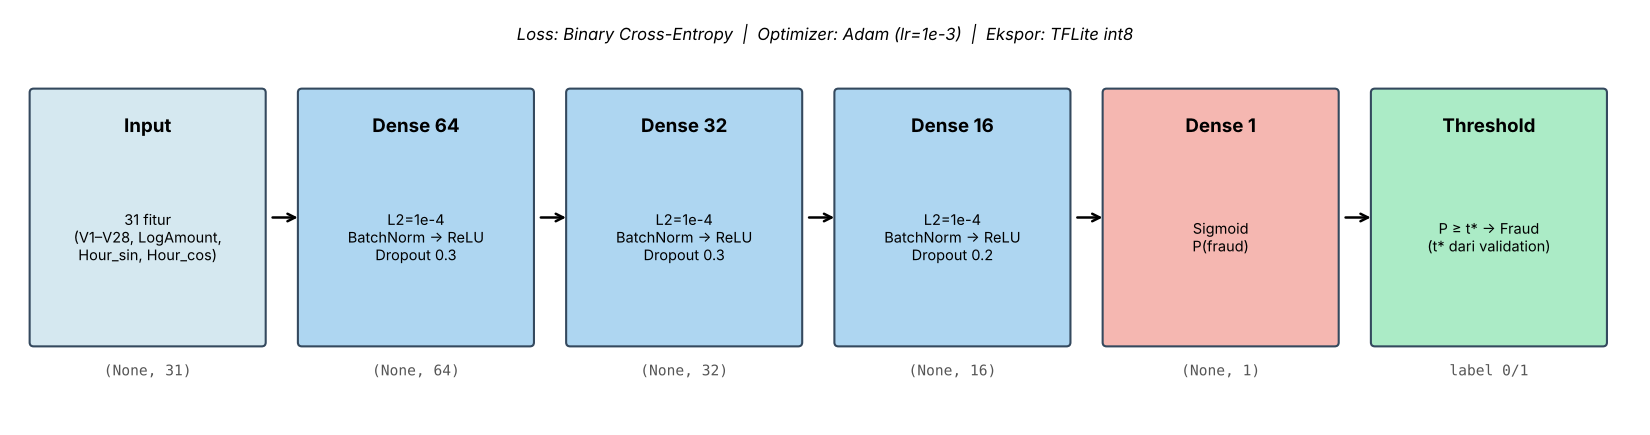

In [10]:
from model import build_dnn, initial_bias
m = build_dnn(X_train.shape[1], output_bias=initial_bias(y_train))
m.summary()
show("model_architecture.png", 900)

## 6. Pelatihan & iterasi perbaikan model
Skenario yang dilatih (`src/train.py`), seluruhnya memakai pipeline `tf.data`:

| Skenario | Loss | Optimizer | Seed |
|---|---|---|---|
| S1 | Binary Cross-Entropy | Adam | 42, 7, 2024 |
| S2 | BCE berbobot kelas | Adam | 42, 7, 2024 |
| S3 | Focal Loss (α=0,75, γ=2) | Adam | 42, 7, 2024 |
| H1–H4 | Focal Loss γ=1/3, arsitektur kecil/besar | Adam | 42 |
| H5 | Binary Cross-Entropy | RMSProp | 42 |

Callback: **EarlyStopping** (monitor `val_pr_auc`, patience 10) dan **ReduceLROnPlateau**
(*learning rate scheduling*, faktor 0,5, patience 4).

In [11]:
import train
if LATIH_ULANG:
    train.main()      # ±20-25 menit di CPU Colab, lebih cepat dengan GPU
else:
    print("Melewati pelatihan: memakai model & hasil di outputs/ yang sudah tersimpan.")

{'rows_raw': 284807, 'missing_values': 0, 'duplicates': 1081, 'duplicates_fraud': 19, 'rows_clean': 283726, 'n_train': 198608, 'fraud_train': 331, 'n_val': 42559, 'fraud_val': 71, 'n_test': 42559, 'fraud_test': 71}
[{'name': 'train', 'element_spec': '(TensorSpec(shape=(None, 31), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))', 'num_batches': 97}, {'name': 'validation', 'element_spec': '(TensorSpec(shape=(None, 31), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))', 'num_batches': 21}, {'name': 'test', 'element_spec': '(TensorSpec(shape=(None, 31), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))', 'num_batches': 21}]


/usr/local/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


S1_baseline_bce    seed=42    ep= 45 PR-AUC=0.8073 ROC=0.9724 | @0.5 P=1.000 R=0.521 F1=0.685 | @0.128 P=0.938 R=0.634 F1=0.756


/usr/local/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


S1_baseline_bce    seed=7     ep= 53 PR-AUC=0.7923 ROC=0.9587 | @0.5 P=0.933 R=0.592 F1=0.724 | @0.281 P=0.922 R=0.662 F1=0.770


/usr/local/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


... (19 outputs left out)

/usr/local/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


H4_focal_large     seed=42    ep= 45 PR-AUC=0.8070 ROC=0.9638 | @0.5 P=0.915 R=0.761 F1=0.831 | @0.544 P=0.930 R=0.746 F1=0.828


/usr/local/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


H5_bce_rmsprop     seed=42    ep= 62 PR-AUC=0.8075 ROC=0.9596 | @0.5 P=0.957 R=0.620 F1=0.752 | @0.057 P=0.898 R=0.746 F1=0.815


In [12]:
import select_final, export_tflite, error_analysis, plots
if LATIH_ULANG:
    select_final.main()    # pilih model final berdasarkan data VALIDATION
    export_tflite.main()   # fitur unik #2
    error_analysis.main()
plots.main()

{
  "selection_table": {
    "S1_baseline_bce": {
      "val_f1_opt_mean": 0.8499053957069225,
      "val_pr_auc_mean": 0.8460147847959919
    },
    "S2_weighted_bce": {
      "val_f1_opt_mean": 0.7704032886303177,
      "val_pr_auc_mean": 0.6813888367117445
    },
    "S3_focal": {
      "val_f1_opt_mean": 0.8345261936811234,
      "val_pr_auc_mean": 0.8343855506183983
    }
  },
  "final_scenario": "S1_baseline_bce",
  "seed": 42,
  "threshold": 0.1276082843542099
}


E0000 00:00:1794240185.555618    1732 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


INFO:tensorflow:Assets written to: /tmp/tmpcmzby478/assets


INFO:tensorflow:Assets written to: /tmp/tmpcmzby478/assets


Saved artifact at '/tmp/tmpcmzby478'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 31), dtype=tf.float32, name='fitur_transaksi')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  140101005709904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140101005718544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140101005716240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140101005717200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140101005709328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140101005713552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140101005717008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140101005721232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140101005710096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140101005713168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140101005720848: Ten

W0000 00:00:1794240188.458042    1732 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1794240188.458078    1732 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.


... (3 outputs left out)

Saved artifact at '/tmp/tmp27z86kv2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 31), dtype=tf.float32, name='fitur_transaksi')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  140101005709904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140101005718544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140101005716240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140101005717200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140101005709328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140101005713552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140101005717008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140101005721232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140101005710096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140101005713168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140101005720848: Ten

W0000 00:00:1794240190.333016    1732 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1794240190.333080    1732 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1794240190.333227    1732 reader.cc:83] Reading SavedModel from: /tmp/tmp27z86kv2
I0000 00:00:1794240190.334195    1732 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1794240190.334207    1732 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp27z86kv2
I0000 00:00:1794240190.343092    1732 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1794240190.395753    1732 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp27z86kv2
I0000 00:00:1794240190.409401    1732 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 76185 microseconds.
/usr/local/lib/python3.13/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is sch

keras               71.9 KB  5.7189 ms  F1=0.7563 P=0.9375 R=0.6338 PR-AUC=0.8073 maxdiff=0.00e+00 agree=1.000000
tflite_fp32         21.0 KB  0.0022 ms  F1=0.7563 P=0.9375 R=0.6338 PR-AUC=0.8073 maxdiff=2.98e-07 agree=1.000000
tflite_int8dyn      10.4 KB  0.0031 ms  F1=0.7667 P=0.9388 R=0.6479 PR-AUC=0.8077 maxdiff=2.65e-02 agree=0.999977


{
  "TP": {
    "n": 45,
    "amount_median": 19.04,
    "V14_median": -7.67866801029943,
    "V17_median": -5.84426647937357,
    "V12_median": -6.16353737959229,
    "p_median": 0.9839054346084595,
    "p_max": 0.9999997615814209
  },
  "FN": {
    "n": 26,
    "amount_median": 5.895,
    "V14_median": -2.059448823853625,
    "V17_median": 0.181977724573678,
    "V12_median": -1.1659466097992075,
    "p_median": 0.013505065813660622,
    "p_max": 0.12513171136379242
  },
  "FP": {
    "n": 3,
    "amount_median": 89.99,
    "V14_median": -10.0066503411988,
    "V17_median": -8.90210626596614,
    "V12_median": -8.2032048307005,
    "p_median": 0.20580163598060608,
    "p_max": 0.27722087502479553
  },
  "normal_V14_median": 0.0611068007846787,
  "normal_V17_median": -0.06730506634687465,
  "FN_p_below_0.01": 13,
  "FN_amounts": [
    0.0,
    0.2,
    0.68,
    0.76,
    0.76,
    0.76,
    0.92,
    1.0,
    1.0,
    1.18,
    2.22,
    3.76,
    3.79,
    8.0,
    12.31,
    18.0,


## 7. Evaluasi

In [13]:
R = json.load(open(RES / "all_results.json"))
rows = []
for r in R:
    rows.append({"skenario": r["scenario"], "seed": r["seed"], "epoch": r["epochs_run"],
                 "thr*": round(r["thr_opt"], 4), "val_F1@thr*": r["val@opt"]["f1"],
                 "test_acc": r["test@opt"]["accuracy"], "test_prec": r["test@opt"]["precision"],
                 "test_rec": r["test@opt"]["recall"], "test_F1@0.5": r["test@0.5"]["f1"],
                 "test_F1@thr*": r["test@opt"]["f1"], "test_PR_AUC": r["test@opt"]["pr_auc"]})
df = pd.DataFrame(rows).round(4)
display(df)
display(df.groupby("skenario")[["val_F1@thr*", "test_F1@thr*", "test_PR_AUC"]].agg(["mean", "std"]).round(4))

,skenario,seed,epoch,thr*,val_F1@thr*,test_acc,test_prec,test_rec,test_F1@0.5,test_F1@thr*,test_PR_AUC
0,S1_baseline_bce,42,45,0.1276,0.8702,0.9993,0.9375,0.6338,0.6852,0.7563,0.8073
1,S1_baseline_bce,7,53,0.2809,0.8462,0.9993,0.9216,0.6620,0.7241,0.7705,0.7923
2,S1_baseline_bce,2024,34,0.0248,0.8333,0.9994,0.8710,0.7606,0.6964,0.8120,0.7845
3,S2_weighted_bce,42,36,0.9999,0.8201,0.9993,0.8644,0.7183,0.2190,0.7846,0.6921
4,S2_weighted_bce,7,13,0.9983,0.7662,0.9991,0.7260,0.7465,0.2670,0.7361,0.6712
5,S2_weighted_bce,2024,13,0.9998,0.7248,0.9991,0.7500,0.6761,0.2463,0.7111,0.6447
6,S3_focal,42,40,0.2045,0.8451,0.9994,0.8548,0.7465,0.7563,0.7970,0.7894
7,S3_focal,7,55,0.3471,0.8333,0.9993,0.8308,0.7606,0.7360,0.7941,0.7642
8,S3_focal,2024,48,0.2555,0.8252,0.9994,0.8710,0.7606,0.7705,0.8120,0.7992
9,H1_focal_gamma1,42,57,0.2411,0.8551,0.9994,0.8983,0.7465,0.7805,0.8154,0.8020


val_F1@thr*         test_F1@thr*         test_PR_AUC        
                       mean     std         mean     std        mean     std
skenario                                                                    
H1_focal_gamma1      0.8551     NaN       0.8154     NaN      0.8020     NaN
H2_focal_gamma3      0.8594     NaN       0.7458     NaN      0.8060     NaN
H3_focal_small       0.8286     NaN       0.7939     NaN      0.7816     NaN
H4_focal_large       0.8593     NaN       0.8281     NaN      0.8070     NaN
H5_bce_rmsprop       0.8511     NaN       0.8154     NaN      0.8075     NaN
S1_baseline_bce      0.8499  0.0187       0.7796  0.0289      0.7947  0.0116
S2_weighted_bce      0.7704  0.0478       0.7439  0.0374      0.6693  0.0238
S3_focal             0.8345  0.0100       0.8010  0.0096      0.7843  0.0181

In [14]:
sel = json.load(open(RES / "final_selection.json"))
print(json.dumps(sel, indent=2))

{
  "selection_table": {
    "S1_baseline_bce": {
      "val_f1_opt_mean": 0.8499053957069225,
      "val_pr_auc_mean": 0.8460147847959919
    },
    "S2_weighted_bce": {
      "val_f1_opt_mean": 0.7704032886303177,
      "val_pr_auc_mean": 0.6813888367117445
    },
    "S3_focal": {
      "val_f1_opt_mean": 0.8345261936811234,
      "val_pr_auc_mean": 0.8343855506183983
    }
  },
  "final_scenario": "S1_baseline_bce",
  "seed": 42,
  "threshold": 0.1276082843542099
}


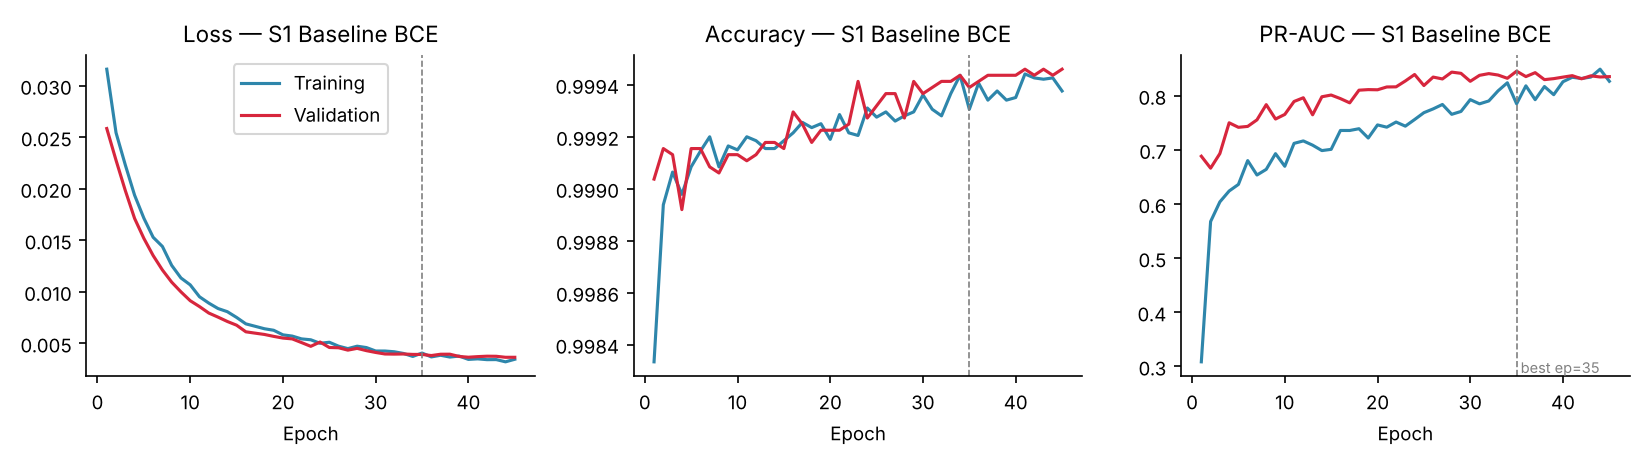

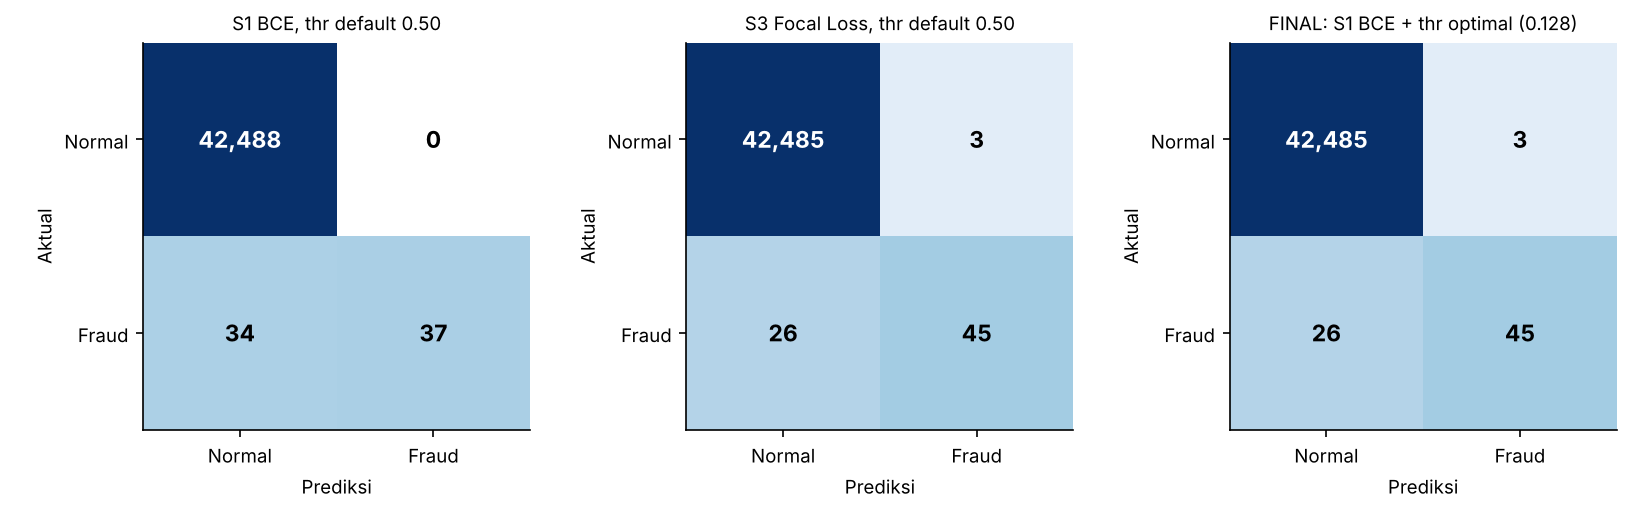

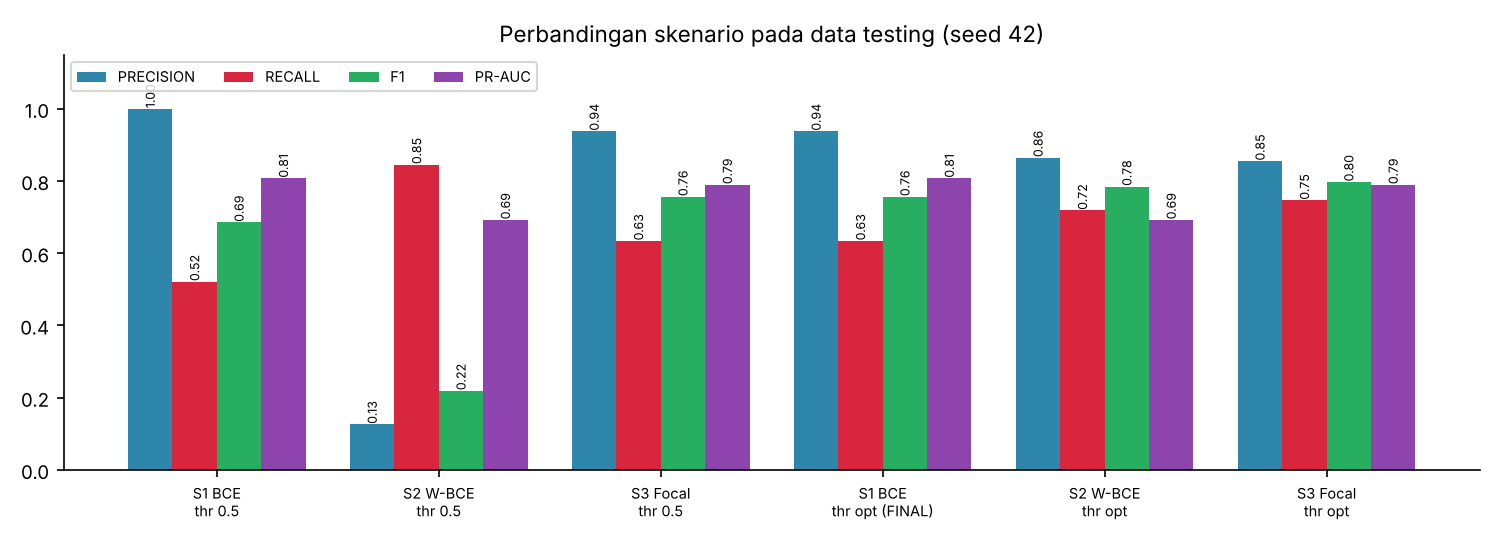

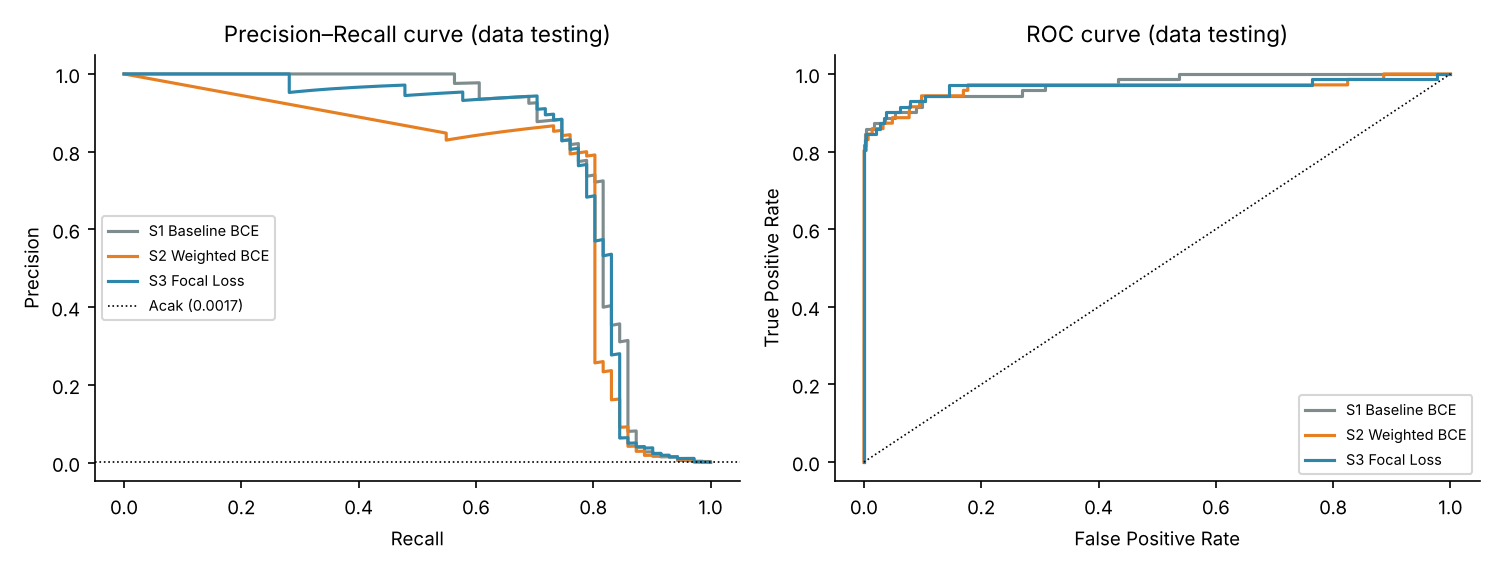

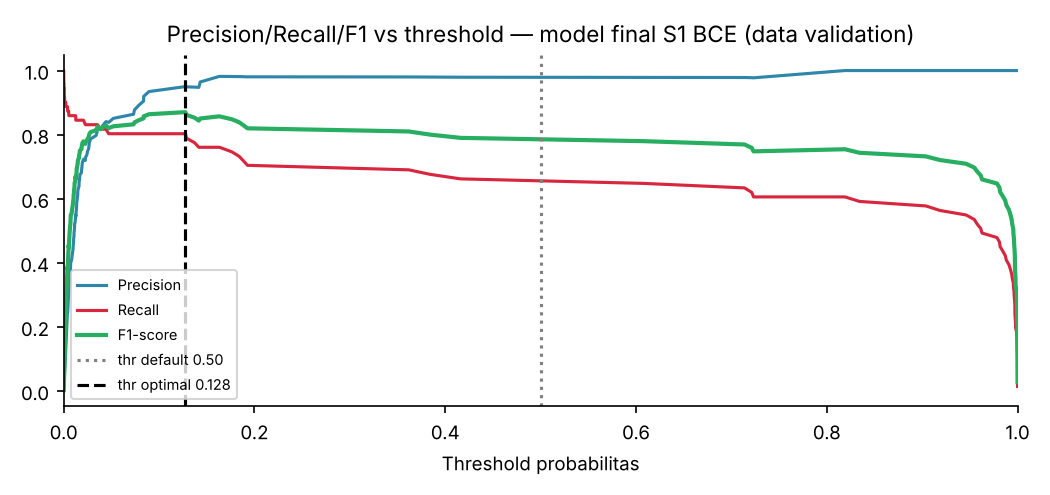

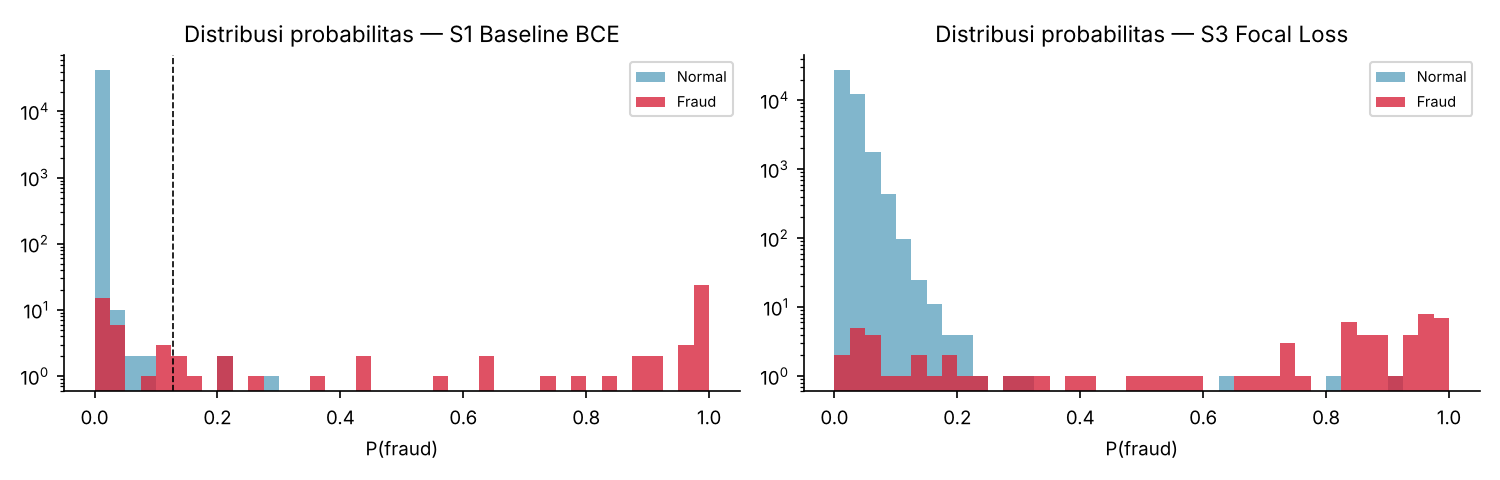

In [15]:
for f in ["res_curves_" + sel["final_scenario"] + ".png", "res_confusion_matrix.png",
          "res_comparison.png", "res_pr_roc.png", "res_threshold.png", "res_score_dist.png"]:
    show(f, 850)

## 8. Fitur unik
1. **Optimasi threshold** — threshold dipilih dari data validation (maksimum F1).
2. **Kompresi TFLite int8** — model 10 KB dengan keputusan yang hampir seluruhnya sama dengan model Keras (lihat kolom *pred_agreement*).

In [16]:
fin = next(r for r in R if r["scenario"] == sel["final_scenario"] and r["seed"] == 42)
print(pd.DataFrame({"thr 0.5": fin["test@0.5"], "thr optimal": fin["test@opt"]}).T
      [["threshold", "precision", "recall", "f1", "tp", "fn", "fp"]].round(4))
tfl = json.load(open(RES / "tflite_results.json"))
pd.DataFrame({k: {"ukuran_KB": v["size_kb"], "latensi_ms": v["latency_ms"],
                  "F1": v["test"]["f1"], "keputusan_sama": v["pred_agreement"]}
              for k, v in tfl.items()}).T.round(4)

             threshold  precision  recall      f1    tp    fn   fp
thr 0.5         0.5000     1.0000  0.5211  0.6852  37.0  34.0  0.0
thr optimal     0.1276     0.9375  0.6338  0.7563  45.0  26.0  3.0


,ukuran_KB,latensi_ms,F1,keputusan_sama
keras,71.8857,5.7189,0.7563,1.0
tflite_fp32,21.0195,0.0022,0.7563,1.0
tflite_int8dyn,10.4375,0.0031,0.7667,1.0


In [17]:
ea = json.load(open(RES / "error_analysis.json"))
display(pd.DataFrame({k: ea[k] for k in ("TP", "FN", "FP")}).T.round(3))
print("Nominal transaksi fraud yang lolos (FN):", ea["FN_amounts"])

,n,amount_median,V14_median,V17_median,V12_median,p_median,p_max
TP,45.0,19.040,-7.679,-5.844,-6.164,0.984,1.000
FN,26.0,5.895,-2.059,0.182,-1.166,0.014,0.125
FP,3.0,89.990,-10.007,-8.902,-8.203,0.206,0.277


Nominal transaksi fraud yang lolos (FN): [0.0, 0.2, 0.68, 0.76, 0.76, 0.76, 0.92, 1.0, 1.0, 1.18, 2.22, 3.76, 3.79, 8.0, 12.31, 18.0, 65.0, 76.94, 99.99, 99.99, 105.99, 239.93, 519.9, 549.06, 1096.99, 1809.68]


## 9. Inferensi dengan model TFLite (dipakai aplikasi Streamlit)

In [18]:
import joblib
from preprocessing import preprocess_raw_rows
try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    Interpreter = tf.lite.Interpreter

scaler = joblib.load(MOD / "scaler.joblib")
thr = json.load(open(MOD / "threshold.json"))["threshold"]
it = Interpreter(model_path=str(MOD / "fraud_dnn_int8dyn.tflite"))

sample = pd.concat([raw[raw.Class == 1].sample(5, random_state=3),
                    raw[raw.Class == 0].sample(5, random_state=3)])
X = preprocess_raw_rows(sample, scaler)
inp, out = it.get_input_details()[0], it.get_output_details()[0]
it.resize_tensor_input(inp["index"], list(X.shape)); it.allocate_tensors()
it.set_tensor(inp["index"], X); it.invoke()
sample = sample.assign(prob_fraud=it.get_tensor(out["index"]).ravel())
sample["prediksi"] = np.where(sample.prob_fraud >= thr, "FRAUD", "Normal")
sample[["Time", "Amount", "Class", "prob_fraud", "prediksi"]].round(4)

/usr/local/lib/python3.13/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,Time,Amount,Class,prob_fraud,prediksi
17480,28755.0,99.99,1,0.1899,FRAUD
16415,27784.0,23.36,1,0.0453,Normal
43681,41607.0,53.95,1,0.9999,FRAUD
261473,160034.0,4.90,1,0.8658,FRAUD
46918,42988.0,648.00,1,0.8918,FRAUD
156961,109263.0,18.96,0,0.0041,Normal
179147,123946.0,0.76,0,0.0000,Normal
15067,26414.0,816.62,0,0.0000,Normal
23204,32637.0,164.01,0,0.0000,Normal
111394,72214.0,2.00,0,0.0003,Normal


## 10. Penyempurnaan UTS

**Validasi input dan deteksi input di luar domain** (`src/input_domain.py`): rentang setiap
fitur pada data latih disimpan ke `outputs/models/input_domain.json`, lalu diukur berapa
transaksi validasi/uji yang berada di luar rentang tersebut.

**Penjelasan prediksi** (`src/explain.py`): kontribusi setiap fitur dihitung dengan *occlusion*
(fitur diganti nilai rata-rata data latih) pada fraud data uji, menggunakan model TFLite.

In [19]:
import runpy
runpy.run_path(str(ROOT / "src" / "input_domain.py"), run_name="__main__")

{
  "validation": {
    "n": 42559,
    "flagged": 8,
    "flagged_pct": 0.018797434150238494,
    "flagged_fraud": 1,
    "fraud": 71
  },
  "testing": {
    "n": 42559,
    "flagged": 6,
    "flagged_pct": 0.01409807561267887,
    "flagged_fraud": 1,
    "fraud": 71
  },
  "contoh_buatan": [
    {
      "input": "Amount 50 EUR, V1\u2013V28 = 0",
      "cek_input": "OK",
      "keterangan": ""
    },
    {
      "input": "Amount 60.000 EUR",
      "cek_input": "DI LUAR DOMAIN",
      "keterangan": "di luar rentang data latih: Amount"
    },
    {
      "input": "V14 = -40",
      "cek_input": "DI LUAR DOMAIN",
      "keterangan": "di luar rentang data latih: V14"
    },
    {
      "input": "Amount -5 EUR",
      "cek_input": "TIDAK VALID",
      "keterangan": "Amount/Time tidak boleh negatif"
    }
  ],
  "domain_amount": [
    0.0,
    19656.5390625
  ],
  "domain_V14": [
    -19.214324951171875,
    10.526765823364258
  ]
}


{'__name__': '__main__',
 '__doc__': 'Penyempurnaan UTS #1 — validasi input dan deteksi input di luar domain data latih.\n\nModel DNN hanya dapat dipercaya pada rentang nilai yang pernah dilihat saat pelatihan.\nModul ini menyimpan rentang (minimum–maksimum) setiap fitur pada DATA LATIH, lalu\nmemeriksa setiap transaksi yang masuk ke aplikasi:\n\n- TIDAK VALID   : ada nilai kosong / bukan angka, Amount negatif, atau Time negatif.\n                  Transaksi ini tidak diprediksi.\n- DI LUAR DOMAIN: satu atau lebih fitur berada di luar rentang data latih.\n                  Transaksi tetap diprediksi, tetapi diberi peringatan agar diperiksa manual.\n\nJalankan `python input_domain.py` untuk membuat outputs/models/input_domain.json dan\nmengevaluasi berapa banyak transaksi validation/testing yang ditandai.\n',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': '/home/claude/proj/src/input_domain.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '

{
  "n_fraud_test": 71,
  "n_tp": 46,
  "n_fn": 25,
  "mean_contrib_tp_top10": {
    "V14": 0.6573328971862793,
    "V10": 0.17794080078601837,
    "V4": 0.1729329228401184,
    "V9": 0.06599176675081253,
    "V21": 0.027198802679777145,
    "V25": 0.014546684920787811,
    "V22": 0.0036099269054830074,
    "Amount": 0.003165840171277523,
    "Time (jam)": 0.0019604123663157225,
    "V3": 0.0014948977623134851
  },
  "top1_feature_count_tp": {
    "V14": 41,
    "V8": 3,
    "V3": 2
  },
  "mean_contrib_fn_top5": {
    "V14": 0.02693261206150055,
    "V4": 0.021958451718091965,
    "V10": 0.015670526772737503,
    "V9": 0.006764384917914867,
    "V25": 0.004689335357397795
  },
  "mean_prob_tp": 0.8046140074729919,
  "mean_prob_fn": 0.02983381226658821
}


/usr/local/lib/python3.13/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


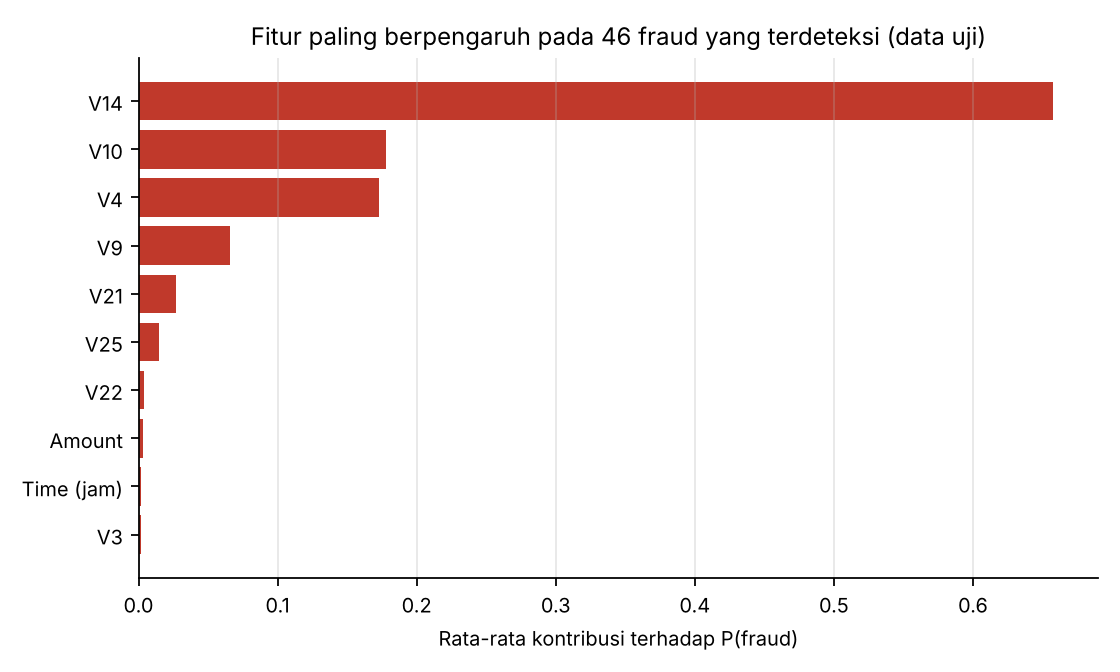

In [20]:
runpy.run_path(str(ROOT / "src" / "explain.py"), run_name="__main__")
show("uts_explain_tp.png", 700)

### Menjalankan aplikasi
```bash
streamlit run app/app.py
```
Aplikasi menerima unggahan CSV berformat sama dengan dataset Kaggle atau input manual satu transaksi.